# Módulo 45: Modelado de datos — Solución
*Juliho Castillo*

Enunciado para estudiantes: [m45-modelado-de-datos-guia.ipynb](m45-modelado-de-datos-guia.ipynb) · Lección: [m45-modelado-de-datos-leccion.ipynb](m45-modelado-de-datos-leccion.ipynb)

## Contexto

Una cadena de tiendas en diez países tiene sus ventas de 2019 a 2021 y sus catálogos de países, clientes, productos y tiendas limpios desde el Módulo 44. Hay que relacionarlos en un **modelo estrella** para que un filtro sobre cualquier catálogo llegue a las ventas en un solo salto, comprobar sus claves y escribir consultas que lo atraviesen. El enunciado original del curso se perdió; las instrucciones de la guía se reconstruyeron a partir de la solución.

In [1]:
import sys
from pathlib import Path

import duckdb
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

DATOS = Path("../practica-ventas/datos-ventas")


def miles(n):
    return f"{int(n):,}".replace(",", " ")

### Tarea 1. Cargar el modelo y clasificar sus tablas

In [2]:
con = practica.conectar()
con.sql("SHOW TABLES").df()

,name
0,calendario
1,clientes
2,paises
3,productos
4,tiendas
5,ventas
6,ventas_detalle


In [3]:
TABLAS = ["ventas", "paises", "clientes", "productos", "tiendas", "calendario"]
TIPO = {"ventas": "hechos"}


def describir(tabla):
    columnas = con.execute(f"DESCRIBE {tabla}").df()
    return {
        "tabla": tabla,
        "tipo": TIPO.get(tabla, "dimensión"),
        "filas": con.execute(f"SELECT count(*) FROM {tabla}").fetchone()[0],
        "columnas": ", ".join(f"{c} ({t})" for c, t in zip(columnas["column_name"], columnas["column_type"])),
    }


pd.set_option("display.max_colwidth", 200)
pd.DataFrame([describir(t) for t in TABLAS])

,tabla,tipo,filas,columnas
0,ventas,hechos,1499000,"fecha (DATE), id_pais (TINYINT), id_tienda (SMALLINT), id_cliente (SMALLINT), id_producto (SMALLINT), cantidad (SMALLINT), precio (SMALLINT), importe (BIGINT)"
1,paises,dimensión,10,"id_pais (BIGINT), pais (VARCHAR)"
2,clientes,dimensión,950,"id_cliente (BIGINT), nombre (VARCHAR), apellido (VARCHAR), correo (VARCHAR), telefono (VARCHAR)"
3,productos,dimensión,1000,"id_producto (BIGINT), categoria (VARCHAR), subcategoria (VARCHAR), producto (VARCHAR)"
4,tiendas,dimensión,200,"id_tienda (BIGINT), tienda (VARCHAR), direccion (VARCHAR), formato (VARCHAR)"
5,calendario,dimensión,1096,"anio (INTEGER), trimestre (INTEGER), mes (INTEGER), nombre_mes (VARCHAR), anio_mes (VARCHAR), fecha (DATE)"


In [4]:
filas, combinaciones = con.execute(
    "SELECT count(*), count(DISTINCT (fecha, id_tienda, id_cliente, id_producto)) FROM ventas"
).fetchone()
print(f"Filas: {miles(filas)} | combinaciones distintas de fecha, tienda, cliente y producto: {miles(combinaciones)}")

Filas: 1 499 000 | combinaciones distintas de fecha, tienda, cliente y producto: 1 498 964


`ventas` es la tabla de hechos: 1 499 000 filas, cada una una línea de venta (un producto vendido a un cliente en una tienda y una fecha). Ni siquiera la combinación de fecha, tienda, cliente y producto es única, así que la tabla no tiene clave natural; no la necesita, porque las claves que importan son las de las dimensiones. `paises`, `clientes`, `productos`, `tiendas` y `calendario` son dimensiones de 10 a 1096 filas. `importe` y `cantidad` son medidas aditivas; `precio` no (se resume con promedio o mediana, nunca sumándolo).

### Tarea 2. Comprobar claves y tipos

In [5]:
def tipo_columna(tabla, columna):
    return con.execute(f"SELECT data_type FROM information_schema.columns WHERE table_name = ? AND column_name = ?",
                       [tabla, columna]).fetchone()[0]


claves = []
for clave, dimension in practica.RELACIONES:
    n, distintas = con.execute(f"SELECT count(*), count(DISTINCT {clave}) FROM {dimension}").fetchone()
    huerfanas = con.execute(f"SELECT count(*) FROM ventas ANTI JOIN {dimension} USING ({clave})").fetchone()[0]
    sin_ventas = con.execute(f"SELECT count(*) FROM {dimension} ANTI JOIN ventas USING ({clave})").fetchone()[0]
    claves.append({
        "dimension": dimension, "clave": clave, "filas": n, "distintas": distintas, "unica": n == distintas,
        "tipo_dimension": tipo_columna(dimension, clave), "tipo_ventas": tipo_columna("ventas", clave),
        "ventas_huerfanas": huerfanas, "claves_sin_ventas": sin_ventas,
    })
pd.DataFrame(claves)

,dimension,clave,filas,distintas,unica,tipo_dimension,tipo_ventas,ventas_huerfanas,claves_sin_ventas
0,paises,id_pais,10,10,True,BIGINT,TINYINT,0,0
1,tiendas,id_tienda,200,200,True,BIGINT,SMALLINT,0,0
2,clientes,id_cliente,950,950,True,BIGINT,SMALLINT,0,0
3,productos,id_producto,1000,1000,True,BIGINT,SMALLINT,0,0


Las cuatro claves son únicas en su dimensión, no hay ventas huérfanas ni claves sin ventas. Los tipos no son idénticos (`BIGINT` en las dimensiones, `TINYINT` o `SMALLINT` en `ventas`, que se guardó con enteros pequeños para ocupar menos), pero son todos enteros y DuckDB los compara sin conversiones de texto: son compatibles.

### Tarea 3. Construir la tabla de relaciones

In [6]:
# ventas_detalle es una vista derivada, no una tabla del modelo
tablas_modelo = [t for t in con.sql("SHOW TABLES").df()["name"] if t not in ("ventas", "ventas_detalle")]
columnas_ventas = set(con.execute("DESCRIBE ventas").df()["column_name"])

candidatas = []
for tabla in sorted(tablas_modelo):
    comunes = columnas_ventas & set(con.execute(f"DESCRIBE {tabla}").df()["column_name"])
    for columna in sorted(comunes):
        n, distintas = con.execute(f"SELECT count(*), count(DISTINCT {columna}) FROM {tabla}").fetchone()
        candidatas.append({"tabla": tabla, "columna_comun": columna, "filas": n, "distintas": distintas})
pd.DataFrame(candidatas)

,tabla,columna_comun,filas,distintas
0,calendario,fecha,1096,1096
1,clientes,id_cliente,950,950
2,paises,id_pais,10,10
3,productos,id_producto,1000,1000
4,tiendas,id_tienda,200,200


Hay cinco candidatas: las cuatro claves de las dimensiones y `fecha`, que relaciona `ventas` con `calendario` (también única en el calendario: 1096 días). Las cinco son válidas. La relación con el calendario se usa en el Módulo 47 para las medidas de tiempo; en este ejercicio documentamos las cuatro dimensiones del enunciado y dejamos el calendario anotado. No hay columnas comunes entre dimensiones, así que no aparece ninguna relación espuria que haya que descartar.

In [7]:
validacion = practica.validar_modelo(con)
relaciones = pd.DataFrame({
    "desde": [f"ventas[{clave}]" for clave, _ in practica.RELACIONES],
    "hacia": [f"{dimension}[{clave}]" for clave, dimension in practica.RELACIONES],
    "clave": [clave for clave, _ in practica.RELACIONES],
    "dimension": [dimension for _, dimension in practica.RELACIONES],
    "cardinalidad": ["*:1" if c == "1:*" else "*:*" for c in validacion["cardinalidad"]],
    "direccion_filtro": [f"{dimension} -> ventas" for _, dimension in practica.RELACIONES],
    "activa": True,
})
relaciones

,desde,hacia,clave,dimension,cardinalidad,direccion_filtro,activa
0,ventas[id_pais],paises[id_pais],id_pais,paises,*:1,paises -> ventas,True
1,ventas[id_tienda],tiendas[id_tienda],id_tienda,tiendas,*:1,tiendas -> ventas,True
2,ventas[id_cliente],clientes[id_cliente],id_cliente,clientes,*:1,clientes -> ventas,True
3,ventas[id_producto],productos[id_producto],id_producto,productos,*:1,productos -> ventas,True


In [8]:
# La misma información que validar_modelo, comparada fila a fila
comparacion = pd.DataFrame(claves)[["dimension", "filas", "distintas", "ventas_huerfanas", "claves_sin_ventas"]]
referencia = validacion.rename(columns={"filas_dimension": "filas", "claves_distintas": "distintas"})
referencia["dimension"] = [dimension for _, dimension in practica.RELACIONES]
pd.testing.assert_frame_equal(
    comparacion.reset_index(drop=True),
    referencia[comparacion.columns].reset_index(drop=True),
    check_dtype=False,
)
validacion

,relacion,filas_dimension,claves_distintas,cardinalidad,ventas_huerfanas,claves_sin_ventas
0,paises[id_pais] -> ventas[id_pais],10,10,1:*,0,0
1,tiendas[id_tienda] -> ventas[id_tienda],200,200,1:*,0,0
2,clientes[id_cliente] -> ventas[id_cliente],950,950,1:*,0,0
3,productos[id_producto] -> ventas[id_producto],1000,1000,1:*,0,0


Las cuatro relaciones son varios a uno (`ventas` en el lado varios), activas y con el filtro de la dimensión hacia los hechos. Las cifras coinciden con `practica.validar_modelo`.

### Tarea 4. Documentar el modelo

In [9]:
def diagrama(relaciones):
    ancho = max(len(d) for d in relaciones["dimension"])
    lineas = ["Modelo estrella (1 = lado uno, * = lado varios; el filtro va de la dimensión a ventas)", ""]
    for r in relaciones.itertuples():
        lineas.append(f"  {r.dimension:>{ancho}} 1 ──────> * ventas    por {r.clave}")
    return "\n".join(lineas)


print(diagrama(relaciones))

Modelo estrella (1 = lado uno, * = lado varios; el filtro va de la dimensión a ventas)

     paises 1 ──────> * ventas    por id_pais
    tiendas 1 ──────> * ventas    por id_tienda
   clientes 1 ──────> * ventas    por id_cliente
  productos 1 ──────> * ventas    por id_producto


In [10]:
CLAVE = {"ventas": "(sin clave natural)", **{d: c for c, d in practica.RELACIONES}, "calendario": "fecha"}
VISIBLES = {
    "ventas": "cantidad, importe (a través de medidas)",
    "paises": "pais",
    "clientes": "nombre, apellido",
    "productos": "categoria, subcategoria, producto",
    "tiendas": "tienda, formato",
    "calendario": "anio, trimestre, mes, nombre_mes, anio_mes",
}
documentacion = pd.DataFrame([describir(t) for t in TABLAS])[["tabla", "tipo", "filas"]]
documentacion["clave"] = documentacion["tabla"].map(CLAVE)
documentacion["columnas_visibles"] = documentacion["tabla"].map(VISIBLES)
documentacion

,tabla,tipo,filas,clave,columnas_visibles
0,ventas,hechos,1499000,(sin clave natural),"cantidad, importe (a través de medidas)"
1,paises,dimensión,10,id_pais,pais
2,clientes,dimensión,950,id_cliente,"nombre, apellido"
3,productos,dimensión,1000,id_producto,"categoria, subcategoria, producto"
4,tiendas,dimensión,200,id_tienda,"tienda, formato"
5,calendario,dimensión,1096,fecha,"anio, trimestre, mes, nombre_mes, anio_mes"


El diagrama sustituye a la captura de la vista de modelo, y la tabla resume lo que verá quien construya el dashboard: columnas descriptivas de las dimensiones y medidas sobre los hechos; las claves `id_*` quedan solo para las uniones. Es lo que hace la vista `ventas_detalle` de `ventas.py`.

### Tarea 5. Consultas que atraviesan las relaciones

In [11]:
categorias_canada = con.sql("""
    SELECT pr.categoria, CAST(sum(v.importe) AS BIGINT) AS ventas_total
    FROM ventas v
    JOIN paises pa USING (id_pais)
    JOIN productos pr USING (id_producto)
    WHERE pa.pais = 'CANADA'
    GROUP BY pr.categoria
    ORDER BY ventas_total DESC
""").df()

referencia = practica.ventas_por(con, "categoria", paises=["CANADA"])[["categoria", "ventas_total"]]
pd.testing.assert_frame_equal(categorias_canada, referencia, check_dtype=False)
categorias_canada

,categoria,ventas_total
0,Technology,2826299532
1,Furniture,2504580878
2,Office Supplies,1352643681


In [12]:
tiendas_muebles = con.sql("""
    SELECT t.id_tienda, t.tienda, t.formato, CAST(sum(v.importe) AS BIGINT) AS ventas_total
    FROM ventas v
    JOIN productos pr USING (id_producto)
    JOIN tiendas t USING (id_tienda)
    WHERE pr.categoria = 'Furniture'
    GROUP BY t.id_tienda, t.tienda, t.formato
    ORDER BY ventas_total DESC
    LIMIT 5
""").df()

referencia = practica.ventas_por(con, ["tienda", "formato"], categorias=["Furniture"]).head(5)
pd.testing.assert_frame_equal(
    tiendas_muebles.drop(columns="id_tienda"), referencia[["tienda", "formato", "ventas_total"]], check_dtype=False
)
tiendas_muebles

,id_tienda,tienda,formato,ventas_total
0,112,Lesch-Wunsch,AAA,86926256
1,190,Gerhold LLC,AA,85572198
2,91,Hansen-Bradtke,AA,85039869
3,167,Treutel-Ullrich,A,85016567
4,28,"Senger, Hegmann and Kuphal",A,84255328


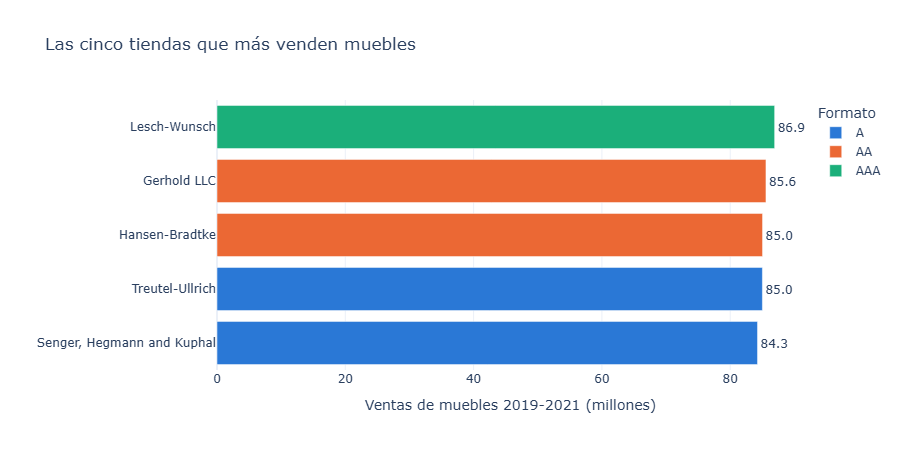

In [13]:
grafico = tiendas_muebles.assign(ventas_millones=tiendas_muebles["ventas_total"] / 1e6)
fig = px.bar(
    grafico.sort_values("ventas_millones"),
    x="ventas_millones", y="tienda", orientation="h", color="formato",
    category_orders={"formato": ["A", "AA", "AAA"], "tienda": grafico["tienda"].tolist()},
    color_discrete_map={"A": "#2a78d6", "AA": "#eb6834", "AAA": "#1baf7a"},
    labels={"ventas_millones": "Ventas de muebles 2019-2021 (millones)", "tienda": "", "formato": "Formato"},
    title="Las cinco tiendas que más venden muebles",
    template="plotly_white",
)
fig.update_traces(texttemplate="%{x:.1f}", textposition="outside", cliponaxis=False)
fig.show()

Las dos consultas filtran por columnas de las dimensiones (`pais`, `categoria`) y coinciden con `practica.ventas_por`. En Canadá, Technology es la categoría que más vende; la tabla y el gráfico muestran las cinco tiendas con más ventas de muebles y su formato.

La consulta de tiendas agrupa por `id_tienda` además del nombre porque el nombre no es único: dos tiendas distintas se llaman igual. Agrupar solo por el nombre las fundiría en una sola fila:

In [14]:
print(con.execute("SELECT count(*), count(DISTINCT tienda) FROM tiendas").fetchone())
practica.ventas_por(con, "tienda", categorias=["Furniture"]).head(3)[["tienda", "ventas_total", "transacciones"]]

(200, 199)


,tienda,ventas_total,transacciones
0,Schumm Inc,158647738,5714
1,Lesch-Wunsch,86926256,2978
2,Gerhold LLC,85572198,2925


Agrupando solo por el nombre, "Schumm Inc" encabeza el ranking con la suma de dos tiendas (la 40 y la 197). Con `["tienda", "formato"]` la comparación anterior es válida porque esas dos tiendas tienen formatos distintos, pero lo seguro es agrupar por la clave.

### Tarea 6. Por qué la clave de la dimensión debe ser única

In [15]:
t_store = pd.read_excel(DATOS / "catalogo.xlsx", sheet_name="t_store", header=2)
con.register("t_store_crudo", t_store)
print(len(t_store), "filas,", t_store["ID_Store"].nunique(), "tiendas distintas")
t_store[t_store["ID_Store"].duplicated(keep=False)].sort_values(["ID_Store", "Status"])

204 filas, 200 tiendas distintas


,ID_Store,Name_Store,Addres,Format,Status
6,17,Rippin LLC,30 Badeau Parkway,AAA,Closed
5,17,Rippin LLC,30 Badeau Parkway,AAA,Open
189,167,Treutel-Ullrich,36 Summer Ridge Center,A,Closed
188,167,Treutel-Ullrich,36 Summer Ridge Center,A,Open
200,188,Schoen-Turcotte,34 Pennsylvania Center,A,Closed
199,188,Schoen-Turcotte,34 Pennsylvania Center,A,Open
202,197,Schumm Inc,0 Killdeer Circle,A,Closed
203,197,Schumm Inc,0 Killdeer Circle,A,Open


In [16]:
filas_ok, total_ok = con.execute("SELECT count(*), sum(importe) FROM ventas").fetchone()
filas_mal, total_mal = con.execute(
    "SELECT count(*), sum(v.importe) FROM ventas v JOIN t_store_crudo t ON v.id_tienda = t.ID_Store"
).fetchone()
filas_rep, total_rep = con.execute("""
    SELECT count(*), sum(importe) FROM ventas
    WHERE id_tienda IN (SELECT ID_Store FROM t_store_crudo GROUP BY ID_Store HAVING count(*) > 1)
""").fetchone()

print(f"ventas sola:                     {miles(filas_ok):>10} filas | {miles(total_ok):>15}")
print(f"ventas JOIN t_store cruda:       {miles(filas_mal):>10} filas | {miles(total_mal):>15}")
print(f"diferencia:                      {miles(filas_mal - filas_ok):>10} filas | {miles(total_mal - total_ok):>15}")
print(f"ventas de las tiendas repetidas: {miles(filas_rep):>10} filas | {miles(total_rep):>15}")
print(f"inflación del total: {(total_mal / total_ok - 1):.2%}")

ventas sola:                      1 499 000 filas |  41 940 958 825
ventas JOIN t_store cruda:        1 529 120 filas |  42 782 781 776
diferencia:                          30 120 filas |     841 822 951
ventas de las tiendas repetidas:     30 120 filas |     841 822 951
inflación del total: 2.01%


Con la dimensión cruda, el ranking de la Tarea 5 también cambia:

In [17]:
con.sql("""
    SELECT t.ID_Store AS id_tienda, t.Name_Store AS tienda, CAST(sum(v.importe) AS BIGINT) AS ventas_total
    FROM ventas v
    JOIN productos pr USING (id_producto)
    JOIN t_store_crudo t ON v.id_tienda = t.ID_Store
    WHERE pr.categoria = 'Furniture'
    GROUP BY t.ID_Store, t.Name_Store
    ORDER BY ventas_total DESC
    LIMIT 5
""").df()

,id_tienda,tienda,ventas_total
0,167,Treutel-Ullrich,170033134
1,17,Rippin LLC,161268376
2,197,Schumm Inc,159002450
3,188,Schoen-Turcotte,143269892
4,112,Lesch-Wunsch,86926256


Las tiendas 17, 167, 188 y 197 aparecen dos veces (`Open` y `Closed`), así que cada una de sus ventas encuentra dos filas en la dimensión y el `JOIN` la duplica: la diferencia de filas y de importe es exactamente lo que vendieron esas cuatro tiendas. En el ranking de muebles, las cuatro tiendas repetidas ocupan los cuatro primeros lugares con el doble de sus ventas reales: Treutel-Ullrich (tienda 167), cuarta en el ranking correcto, pasa al primero. No hay ningún error ni aviso, solo cifras infladas; por eso la dimensión se limpia antes (quedándose con la fila `Open`, como hace `practica.leer_tiendas`) y se comprueba con `validar_modelo`.

**Revisión posterior (2026-10):** El ejercicio se resolvió originalmente en Power BI (vista de modelo y administración de relaciones), con una captura del diagrama como evidencia. Se rehízo en Python con DuckDB, pandas y Plotly para que la sección no dependa de software de pago ni de Windows; la versión original sigue en el historial de git.